<a href="https://colab.research.google.com/github/ilhamajikusuma/25523172_Regresi_FSD/blob/main/A%20%E2%80%93%20Liner%20Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Bagian A – Linerar Regression**
Nama: ILHAM AJI KUSUMA

NIM: 25523172

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_`selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

sns.set_theme(style='whitegrid')

# **A1 – Deskripsi Dataset**

In [ ]:
df = pd.read_csv('/content/sample_data/california_housing_train.csv')
print(df.shape)
df.info()
df.head()

(17000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


## A1 – Deskripsi Dataset

**Sumber:** California Housing (data sensus California tahun 1990), tersedia di folder `sample_data` Google Colab (`california_housing_train.csv`). Dataset asli berasal dari Pace & Barry (1997) dan juga tersedia di Kaggle/scikit-learn.

**Ukuran:** 17.000 baris dan 9 kolom. Setiap baris mewakili satu *block group* (kelompok blok sensus), bukan satu rumah.

**Arti kolom:**
- `longitude`: garis bujur lokasi block group
- `latitude`: garis lintang lokasi block group
- `housing_median_age`: median usia rumah (tahun)
- `total_rooms`: total ruangan seluruh rumah di block group
- `total_bedrooms`: total kamar tidur seluruh rumah di block group
- `population`: jumlah penduduk di block group
- `households`: jumlah rumah tangga di block group
- `median_income`: median pendapatan rumah tangga (satuan puluhan ribu USD)
- `median_house_value`: median nilai rumah (USD)

**Variabel target:** `median_house_value` (numerik kontinu, dalam USD). Kedelapan kolom lain menjadi kandidat fitur.

# **A2 – Eksplorasi dan Visualisasi**

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,17000.0,-119.562108,2.005166,-124.3500,-121.790000,-118.4900,-118.000,-114.3100
latitude,17000.0,35.625225,2.137340,32.5400,33.930000,34.2500,37.720,41.9500
housing_median_age,17000.0,28.589353,12.586937,1.0000,18.000000,29.0000,37.000,52.0000
total_rooms,17000.0,2643.664412,2179.947071,2.0000,1462.000000,2127.0000,3151.250,37937.0000
total_bedrooms,17000.0,539.410824,421.499452,1.0000,297.000000,434.0000,648.250,6445.0000
population,17000.0,1429.573941,1147.852959,3.0000,790.000000,1167.0000,1721.000,35682.0000
households,17000.0,501.221941,384.520841,1.0000,282.000000,409.0000,605.250,6082.0000
median_income,17000.0,3.883578,1.908157,0.4999,2.566375,3.5446,4.767,15.0001
median_house_value,17000.0,207300.912353,115983.764387,14999.0000,119400.000000,180400.0000,265000.000,500001.0000


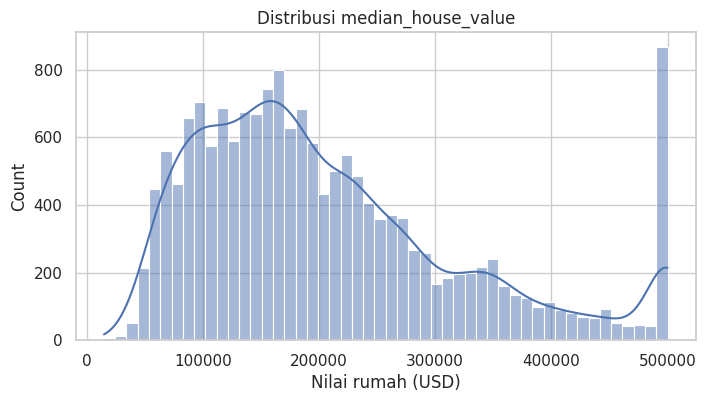

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df['median_house_value'], bins=50, kde=True)
plt.title('Distribusi median_house_value')
plt.xlabel('Nilai rumah (USD)')
plt.show()

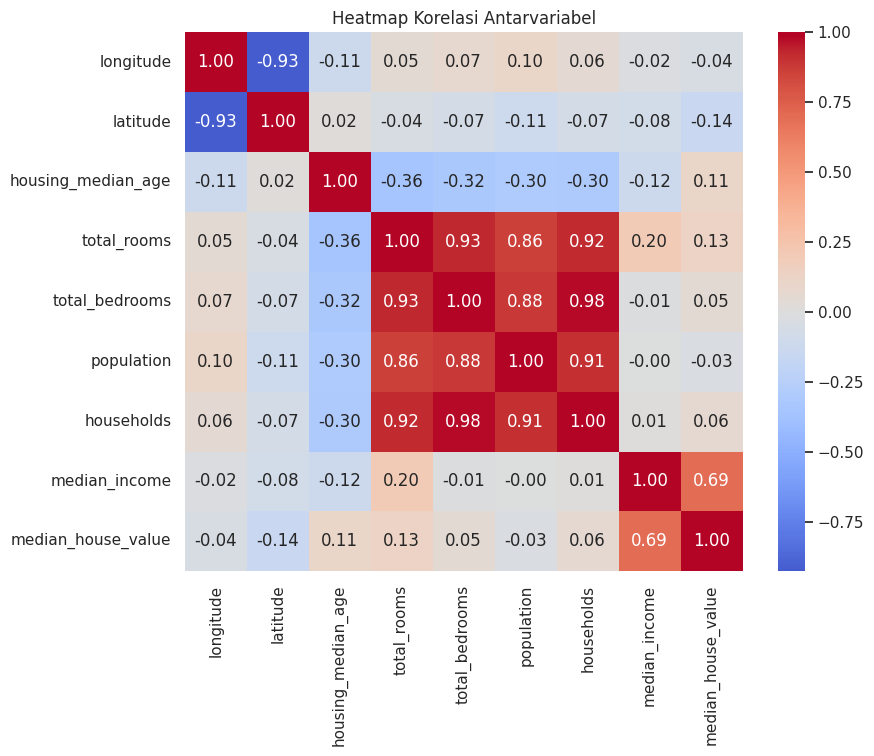

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi Antarvariabel')
plt.show()

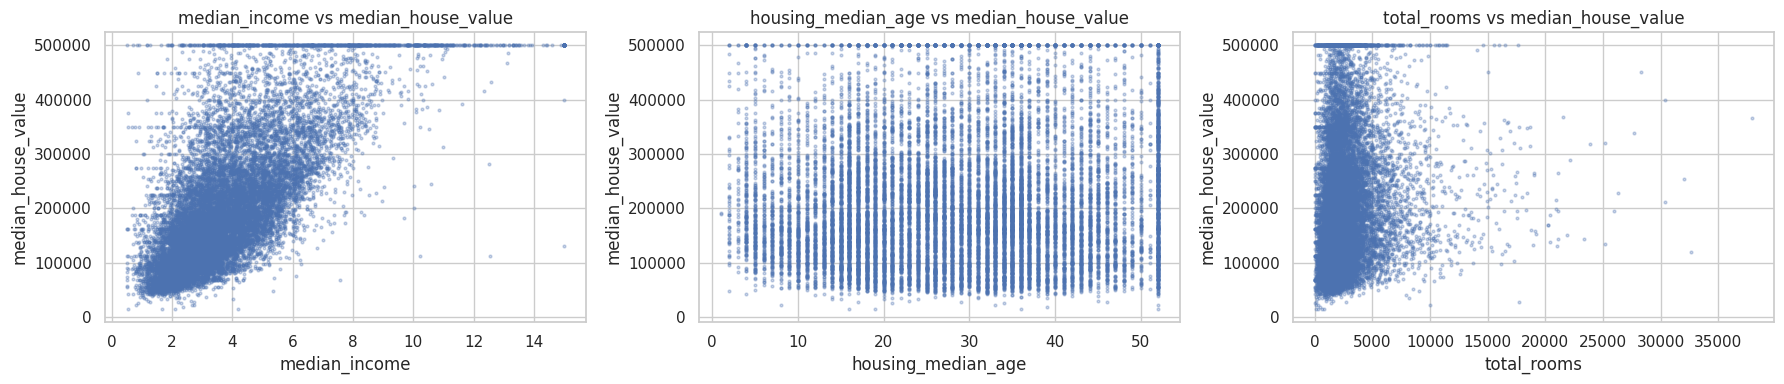

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['median_income', 'housing_median_age', 'total_rooms']):
    ax.scatter(df[col], df['median_house_value'], s=4, alpha=0.3)
    ax.set_xlabel(col)
    ax.set_ylabel('median_house_value')
    ax.set_title(f'{col} vs median_house_value')
plt.tight_layout()
plt.show()

## A2 – Eksplorasi dan Visualisasi Data

**Statistik deskriptif.** Tabel `describe()` menunjukkan skala kolom sangat berbeda (misalnya `median_income` bernilai satuan, sedangkan `total_rooms` bernilai ribuan). Kolom `total_rooms`, `total_bedrooms`, `population`, dan `households` memiliki nilai maksimum yang jauh di atas rata-rata, yang mengindikasikan adanya outlier.

**Histogram target.** Distribusi `median_house_value` condong ke kanan (right-skewed). Terdapat lonjakan frekuensi di nilai maksimum (sekitar 500.000 USD). Ini menandakan data target dipotong (*capped*) pada batas atas, sehingga rumah yang sebenarnya lebih mahal tetap tercatat 500.001.

**Heatmap korelasi.** `median_income` memiliki korelasi positif terkuat dengan target. Fitur `total_rooms`, `total_bedrooms`, `population`, dan `households` saling berkorelasi sangat tinggi (di atas 0,85), sehingga ada indikasi multikolinearitas. `latitude` dan `longitude` juga berkorelasi negatif kuat satu sama lain karena bentuk garis pantai California.

**Scatter plot.** `median_income` menunjukkan pola linear naik yang jelas terhadap harga. `housing_median_age` dan `total_rooms` menunjukkan hubungan yang lemah dengan titik tersebar luas. Pada scatter `median_income` terlihat garis horizontal di harga 500.000 akibat pemotongan target tadi.

# **A3 – Preprocessing**

In [ ]:
print('Missing values per kolom:')
print(df.isnull().sum())
print('Jumlah data duplikat:', df.duplicated().sum())

Missing values per kolom:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64
Jumlah data duplikat: 0


In [ ]:
df = df.drop_duplicates()
n_capped = (df['median_house_value'] >= 500001).sum()
print('Baris dengan target di batas atas (500001):', n_capped)
df = df[df['median_house_value'] < 500001].copy()
print('Ukuran data setelah dibersihkan:', df.shape)

Baris dengan target di batas atas (500001): 814
Ukuran data setelah dibersihkan: (16186, 9)


Jumlah outlier (aturan IQR) per fitur:
longitude                0
latitude                 0
housing_median_age       0
total_rooms           1049
total_bedrooms        1023
population             950
households             983
median_income          295
dtype: int64


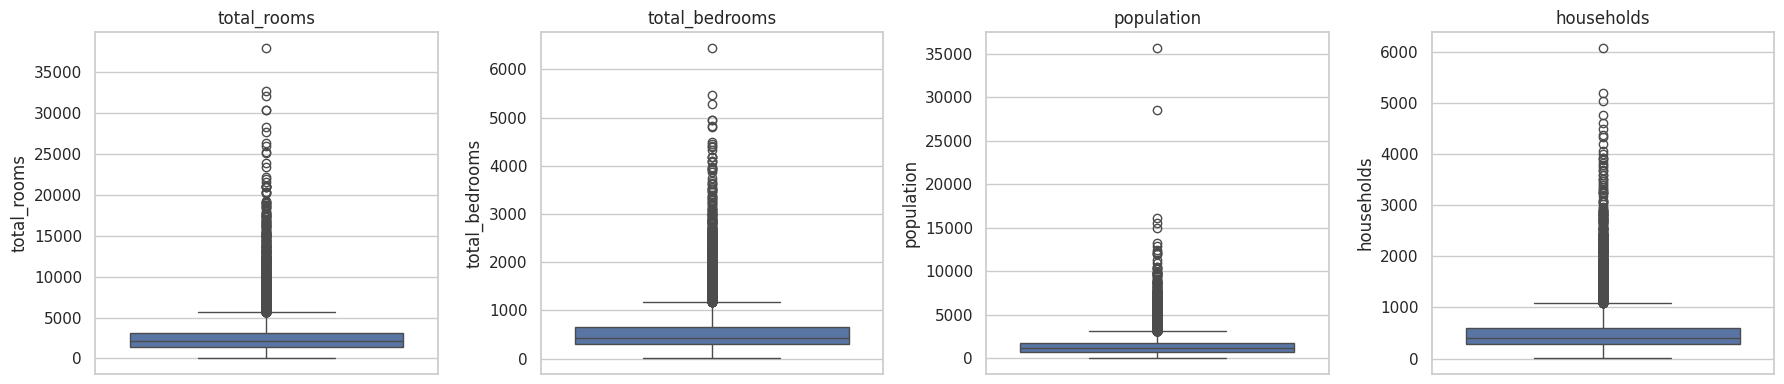

In [ ]:
fitur_awal = df.drop(columns='median_house_value').columns
Q1 = df[fitur_awal].quantile(0.25)
Q3 = df[fitur_awal].quantile(0.75)
IQR = Q3 - Q1
jumlah_outlier = ((df[fitur_awal] < Q1 - 1.5 * IQR) | (df[fitur_awal] > Q3 + 1.5 * IQR)).sum()
print('Jumlah outlier (aturan IQR) per fitur:')
print(jumlah_outlier)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['total_rooms', 'total_bedrooms', 'population', 'households']):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
kolom_skewed = ['total_rooms', 'total_bedrooms', 'population', 'households']
for col in kolom_skewed:
    batas = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=batas)
df[kolom_skewed].describe().T

,count,mean,std,min,25%,50%,75%,max
total_rooms,16186.0,2581.103447,1863.740897,2.0,1453.00,2113.0,3124.00,11312.20
total_bedrooms,16186.0,534.356784,378.492204,2.0,298.00,435.0,650.75,2279.45
population,16186.0,1424.203917,994.864894,3.0,799.25,1180.0,1743.75,6000.30
households,16186.0,496.356975,343.401017,2.0,283.00,410.0,607.00,2060.00


## A3 – Preprocessing

**Missing values.** Tidak ditemukan missing values, sehingga tidak perlu imputasi atau penghapusan baris.

**Data duplikat.** Dicek dengan `duplicated()`; jika ada, dihapus agar tidak menggandakan bobot sebagian observasi.

**Target yang terpotong.** Baris dengan `median_house_value` = 500.001 dihapus. Nilai ini bukan harga sebenarnya, melainkan batas atas pencatatan. Jika dipertahankan, model akan belajar dari target yang bias dan garis regresi tertarik ke bawah pada rumah mahal. Konsekuensinya, model ini tidak cocok untuk memprediksi rumah di atas batas tersebut.

**Outlier.** Outlier dideteksi dengan aturan IQR dan boxplot. Empat fitur ukuran (`total_rooms`, `total_bedrooms`, `population`, `households`) punya ekor kanan yang panjang. Outlier tidak dihapus karena bisa jadi block group yang memang besar, bukan kesalahan data. Sebagai gantinya nilainya dibatasi (*clipping*) pada persentil ke-99 supaya tidak terlalu mempengaruhi garis regresi.

**Encoding.** Tidak diperlukan karena semua fitur numerik.

**Scaling.** Linear Regression berbasis OLS tidak memerlukan scaling untuk akurasi prediksi, jadi model utama dilatih pada data asli agar koefisiennya mudah diinterpretasikan dalam satuan aslinya. Scaling hanya dipakai pada A6 untuk membandingkan besar pengaruh antarfitur.

# **A4 – Pemilihan Fitur**

In [ ]:
korelasi_target = df.corr()['median_house_value'].drop('median_house_value').sort_values(ascending=False)
print(korelasi_target)

median_income         0.645729
total_rooms           0.154534
households            0.098577
total_bedrooms        0.077835
housing_median_age    0.068057
population            0.008480
longitude            -0.043938
latitude             -0.150570
Name: median_house_value, dtype: float64


In [ ]:
X_semua = add_constant(df.drop(columns='median_house_value'))
vif = pd.DataFrame({
    'fitur': X_semua.columns,
    'VIF': [variance_inflation_factor(X_semua.values, i) for i in range(X_semua.shape[1])]
})
vif[vif['fitur'] != 'const'].sort_values('VIF', ascending=False)

,fitur,VIF
5,total_bedrooms,36.460327
7,households,35.378877
4,total_rooms,13.824500
2,latitude,9.151599
1,longitude,8.906264
6,population,6.757404
8,median_income,1.936664
3,housing_median_age,1.324294


In [ ]:
fitur_terpilih = ['median_income', 'housing_median_age', 'total_rooms', 'population', 'latitude', 'longitude']

X_cek = add_constant(df[fitur_terpilih])
vif_akhir = pd.DataFrame({
    'fitur': X_cek.columns,
    'VIF': [variance_inflation_factor(X_cek.values, i) for i in range(X_cek.shape[1])]
})
vif_akhir[vif_akhir['fitur'] != 'const'].sort_values('VIF', ascending=False)

,fitur,VIF
5,latitude,8.512215
6,longitude,8.289835
3,total_rooms,4.901302
4,population,4.593502
1,median_income,1.371070
2,housing_median_age,1.319307


## A4 – Pemilihan Fitur

Pemilihan fitur menggunakan dua analisis: korelasi dengan target dan VIF (*Variance Inflation Factor*) untuk multikolinearitas.

**Fitur dipertahankan:**
- `median_income`: korelasi terkuat dengan target.
- `housing_median_age`: informasi usia bangunan yang tidak tumpang tindih dengan fitur lain.
- `total_rooms` dan `population`: mewakili ukuran block group.
- `latitude` dan `longitude`: lokasi sangat menentukan harga rumah. Keduanya berkorelasi satu sama lain sehingga VIF-nya tinggi, tetapi tetap dipertahankan karena informasi lokasinya penting dan tidak ada fitur lain yang menggantikannya. Konsekuensinya, koefisien keduanya sebaiknya dibaca sebagai satu kesatuan.

**Fitur dibuang:**
- `total_bedrooms` dan `households`: berkorelasi sangat tinggi dengan `total_rooms` dan `population` (di atas 0,85) dan VIF-nya besar. Informasinya sudah terwakili fitur lain, sehingga dibuang untuk mengurangi multikolinearitas dan membuat koefisien lebih stabil.

# **A5 – Pembagian Data**

In [ ]:
X = df[fitur_terpilih]
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Data latih :', X_train.shape)
print('Data uji   :', X_test.shape)

Data latih : (12948, 6)
Data uji   : (3238, 6)


## A5 – Pembagian Data

Data dibagi menjadi 80% data latih dan 20% data uji dengan `train_test_split`. `random_state=42` ditetapkan agar pembagian sama setiap kali notebook dijalankan sehingga hasil dapat direproduksi. Data uji tidak disentuh selama pelatihan dan hanya dipakai untuk menilai kemampuan model pada data baru.

# **A6 – Pemodelan**

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

koef = pd.DataFrame({'fitur': fitur_terpilih, 'koefisien': model.coef_})
print('Intercept:', model.intercept_)
koef

Intercept: -3753879.664090677


,fitur,koefisien
0,median_income,32762.499993
1,housing_median_age,973.065884
2,total_rooms,15.408104
3,population,-24.110334
4,latitude,-44749.848454
5,longitude,-45063.486811


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
model_s = LinearRegression().fit(X_train_s, y_train)

koef_std = pd.DataFrame({'fitur': fitur_terpilih, 'koefisien_terstandarisasi': model_s.coef_})
koef_std['pengaruh_absolut'] = koef_std['koefisien_terstandarisasi'].abs()
koef_std.sort_values('pengaruh_absolut', ascending=False)

,fitur,koefisien_terstandarisasi,pengaruh_absolut
4,latitude,-96048.523100,96048.523100
5,longitude,-90384.372212,90384.372212
0,median_income,51904.747513,51904.747513
2,total_rooms,29157.986917,29157.986917
3,population,-24196.564761,24196.564761
1,housing_median_age,12225.100661,12225.100661


## A6 – Pemodelan

Model `LinearRegression` dilatih pada data latih. Persamaannya:

harga = intercept + (b1 × median_income) + (b2 × housing_median_age) + ... + (b6 × longitude)

**Interpretasi koefisien** (menahan fitur lain tetap, *ceteris paribus*):
- `median_income`: setiap kenaikan 1 satuan (sekitar 10.000 USD) pendapatan median, harga median rumah naik sebesar koefisiennya. Nilainya positif dan besar, sesuai dugaan bahwa daerah berpendapatan tinggi punya rumah lebih mahal.
- `housing_median_age`: koefisien menunjukkan perubahan harga per tambahan satu tahun usia rumah.
- `total_rooms` dan `population`: koefisien menunjukkan perubahan harga per tambahan satu ruangan/penduduk. Nilainya kecil karena skala fiturnya besar.
- `latitude` dan `longitude`: koefisien negatif berarti harga cenderung turun saat bergerak ke utara dan ke timur (menjauh dari pesisir selatan). Karena keduanya berkorelasi kuat, interpretasinya dibaca bersama sebagai efek lokasi.
- **Intercept**: harga prediksi saat semua fitur bernilai nol. Nilai ini tidak punya makna praktis karena kombinasi nol tidak realistis.

Koefisien pada tabel pertama tidak bisa dibandingkan langsung karena satuan fitur berbeda. Tabel kedua memakai fitur yang distandarisasi hanya untuk membandingkan besar pengaruh antarfitur.

# **A7 – Evaluasi**

In [ ]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

def hitung_metrik(y_asli, y_pred):
    mse = mean_squared_error(y_asli, y_pred)
    return {
        'MAE': mean_absolute_error(y_asli, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_asli, y_pred)
    }

hasil = pd.DataFrame({
    'Data Latih': hitung_metrik(y_train, y_pred_train),
    'Data Uji': hitung_metrik(y_test, y_pred_test)
}).T
hasil

,MAE,MSE,RMSE,R2
Data Latih,47921.329876,4.062807e+09,63740.148956,0.579414
Data Uji,47146.618031,3.999477e+09,63241.414485,0.573194


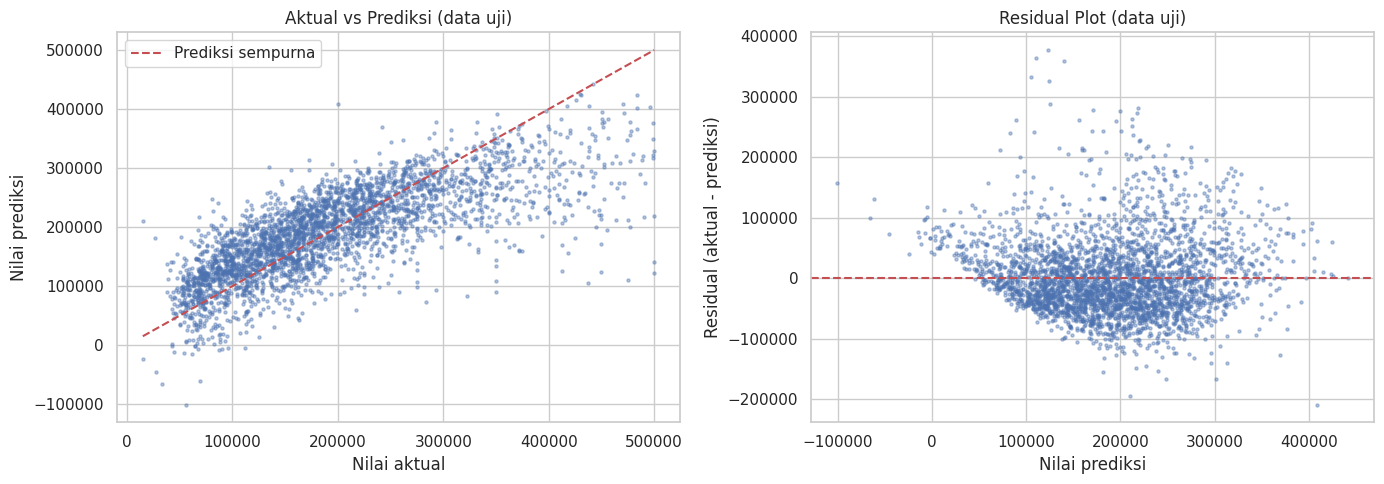

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_test, s=5, alpha=0.4)
batas = [y_test.min(), y_test.max()]
axes[0].plot(batas, batas, 'r--', label='Prediksi sempurna')
axes[0].set_xlabel('Nilai aktual')
axes[0].set_ylabel('Nilai prediksi')
axes[0].set_title('Aktual vs Prediksi (data uji)')
axes[0].legend()

residual = y_test - y_pred_test
axes[1].scatter(y_pred_test, residual, s=5, alpha=0.4)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('Nilai prediksi')
axes[1].set_ylabel('Residual (aktual - prediksi)')
axes[1].set_title('Residual Plot (data uji)')

plt.tight_layout()
plt.show()

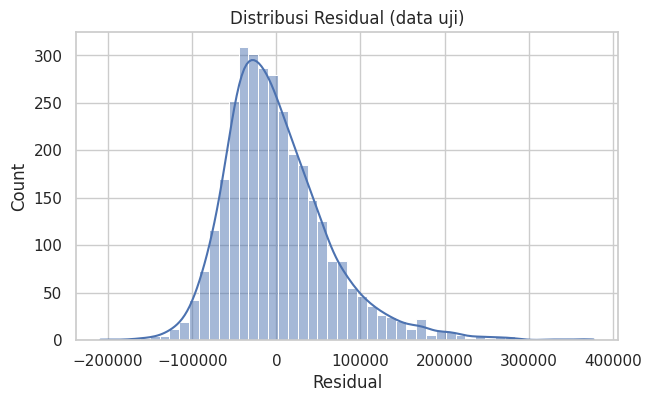

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(residual, bins=50, kde=True)
plt.title('Distribusi Residual (data uji)')
plt.xlabel('Residual')
plt.show()

## A7 – Evaluasi

Model dievaluasi dengan MAE, MSE, RMSE, dan R² pada data latih dan data uji (lihat tabel di atas).

- **MAE**: rata-rata selisih absolut prediksi dan nilai aktual, dalam USD.
- **MSE**: rata-rata kuadrat selisih; menghukum kesalahan besar lebih berat.
- **RMSE**: akar MSE, satuannya sama dengan target sehingga mudah ditafsirkan.
- **R²**: proporsi variasi harga yang dijelaskan model (1 = sempurna, 0 = tidak lebih baik dari menebak rata-rata).

Plot aktual vs prediksi dan residual ada di bawah tabel. Pembahasan dibuat di A8.

# **A8 – Analisis Performa**

In [ ]:
selisih_r2 = hasil.loc['Data Latih', 'R2'] - hasil.loc['Data Uji', 'R2']
rmse_uji = hasil.loc['Data Uji', 'RMSE']
rata_target = y_test.mean()

print(f"R2 latih            : {hasil.loc['Data Latih', 'R2']:.3f}")
print(f"R2 uji              : {hasil.loc['Data Uji', 'R2']:.3f}")
print(f"Selisih R2          : {selisih_r2:.3f}")
print(f"RMSE latih          : {hasil.loc['Data Latih', 'RMSE']:,.0f}")
print(f"RMSE uji            : {rmse_uji:,.0f}")
print(f"MAE uji             : {hasil.loc['Data Uji', 'MAE']:,.0f}")
print(f"Rata-rata target uji: {rata_target:,.0f}")
print(f"RMSE uji / rata-rata: {rmse_uji / rata_target:.1%}")
print()
print("Urutan pengaruh fitur (koefisien terstandarisasi):")
print(koef_std.sort_values('pengaruh_absolut', ascending=False)[['fitur', 'koefisien_terstandarisasi']].to_string(index=False))

R2 latih            : 0.579
R2 uji              : 0.573
Selisih R2          : 0.006
RMSE latih          : 63,740
RMSE uji            : 63,241
MAE uji             : 47,147
Rata-rata target uji: 190,933
RMSE uji / rata-rata: 33.1%

Urutan pengaruh fitur (koefisien terstandarisasi):
             fitur  koefisien_terstandarisasi
          latitude              -96048.523100
         longitude              -90384.372212
     median_income               51904.747513
       total_rooms               29157.986917
        population              -24196.564761
housing_median_age               12225.100661


## A8 – Analisis Performa

**Kemampuan prediksi.** Pada data uji, model memperoleh R² sebesar 0,573, artinya model menjelaskan sekitar 57,3% variasi harga rumah. RMSE data uji sebesar 63.241 USD dan MAE sebesar 47.147 USD. Dibandingkan rata-rata harga data uji (190.933 USD), RMSE setara sekitar 33,1% dari rata-rata. Artinya model sudah menangkap pola utama harga, tetapi prediksinya masih meleset cukup jauh: rata-rata kesalahan sekitar 47 ribu USD per prediksi. Performa ini tergolong sedang dan belum cukup andal untuk dipakai sebagai estimasi harga yang presisi.

**Overfitting atau underfitting.** R² data latih adalah 0,579 dan R² data uji 0,573, selisihnya hanya 0,006. RMSE latih (63.740) dan RMSE uji (63.241) juga hampir sama. Karena performa pada data latih dan uji nyaris identik, model **tidak mengalami overfitting** dan mampu menggeneralisasi dengan baik ke data baru. Namun R² yang hanya sekitar 0,57 pada kedua data menunjukkan **kecenderungan underfitting**: model linear terlalu sederhana untuk menangkap hubungan antara fitur dan harga yang sebenarnya tidak linear.

**Fitur paling berpengaruh.** Berdasarkan koefisien terstandarisasi, fitur dengan pengaruh terbesar adalah `latitude` (-96.049) dan `longitude` (-90.384), diikuti `median_income` (51.905), `total_rooms` (29.158), `population` (-24.197), dan `housing_median_age` (12.225). Artinya lokasi geografis adalah faktor paling dominan dalam menentukan harga rumah, lebih besar daripada pendapatan. Perlu diingat bahwa `latitude` dan `longitude` berkorelasi kuat, sehingga besarnya koefisien keduanya sebaiknya dibaca sebagai satu efek lokasi gabungan, bukan dua pengaruh yang terpisah. Di antara fitur lainnya, `median_income` memiliki pengaruh terbesar: daerah berpendapatan lebih tinggi memiliki harga rumah lebih tinggi. `housing_median_age` memiliki kontribusi paling kecil.

**Pola residual.** Pada plot aktual vs prediksi, titik-titik menyebar lebar di sekitar garis diagonal. Model cenderung memprediksi terlalu tinggi untuk rumah murah (di bawah sekitar 100.000 USD) dan terlalu rendah untuk rumah mahal (di atas sekitar 300.000 USD), sehingga prediksi seolah "mendatar" di kisaran 250.000-300.000 USD. Residual plot memperkuat hal ini: residual tidak tersebar acak di sekitar nol, melainkan membentuk pola dengan banyak residual negatif di rentang prediksi menengah dan ekor positif yang panjang, serta sebaran yang melebar pada prediksi menengah hingga tinggi (heteroskedastisitas). Histogram residual juga condong ke kanan (puncak di sekitar -30.000 dengan ekor hingga lebih dari 300.000), sehingga residual tidak berdistribusi simetris atau normal. Temuan ini menunjukkan asumsi linearitas dan varians konstan tidak sepenuhnya terpenuhi, dan ada pola nonlinear yang tidak tertangkap model. Ini konsisten dengan R² yang hanya 0,573 dan kesimpulan underfitting.

**Keterbatasan model.**
1. Model mengasumsikan hubungan linear. Pengaruh lokasi terhadap harga sebenarnya tidak linear (harga tinggi di kawasan pesisir tertentu dan turun di pedalaman), sehingga model linear sulit menangkapnya dan menjadi penyebab utama underfitting.
2. Baris dengan harga terpotong di 500.001 dihapus, sehingga model tidak cocok untuk memprediksi rumah di segmen harga tertinggi.
3. `latitude` dan `longitude` berkorelasi kuat (multikolinearitas), sehingga koefisien keduanya tidak stabil bila ditafsirkan sendiri-sendiri.
4. Data berasal dari sensus 1990 dan berupa agregat per block group, bukan per rumah, sehingga prediksi tidak berlaku untuk harga rumah saat ini atau rumah individual.
5. Model menghasilkan beberapa prediksi negatif (terlihat pada plot aktual vs prediksi), padahal harga rumah tidak mungkin negatif. Ini terjadi karena Linear Regression tidak membatasi rentang keluaran. Transformasi log pada target dapat mengatasi hal ini.
6. Perbaikan yang mungkin dilakukan: menambah fitur turunan (misalnya rasio ruangan per rumah tangga atau jarak ke pusat kota), transformasi log pada target, atau mencoba model nonlinear seperti Random Forest.